# Recorded FWI trajectories: cycle skipping and negative controls

**Question:** What do committed multiscale FWI histories show about training and withheld waveforms, and what fails on the cycle-skip control?
**Level 3 — Research experiment** · 60–90 min · wave propagation and optimization

## Objectives
- Read the product's Deepwave acoustic objective, parameterization, continuation schedule and evaluation contract.
- Scrub recorded optimizer states to examine iteration effects; no fresh solve is launched.
- Compare recorded regularization cases on identical synthetic observations; this is saved-run analysis, not a new solve.
- Inspect the designated cycle-skipping challenge, including a held-out waveform residual.

## Setup

Run from repository root in the pinned notebook environment:
pip install numpy==2.2.6 scipy==1.15.2 matplotlib==3.10.8

The experiment cell prints active package versions.

## Data
These are committed **synthetic** Deepwave solver artifacts. Iteration and regularization experiments replay stored states; they do not launch a GPU solve. The cycle-skipping challenge remains a negative control. Nothing here is field data or proof that FWI works for arbitrary user input.

## Method

The product implementation in data-pipeline/seismic.py solves the 2D acoustic scalar wave equation with Deepwave, differentiates the waveform objective automatically, and updates bounded velocity using L-BFGS with strong-Wolfe line search. Four progressively finer control grids and a physical-gradient penalty are used. The recorded objective is approximately

Φ(m)=||P_A B_f(F(m)−d)||²₂ / ||P_A B_f d||²₂ + βR(m)

where F(m) is the simulated gather, d the synthetic observation, P_A selects training receivers and B_f is the zero-phase filter for the current continuation stage. Receiver indices i mod 5 = 2 are excluded from the objective and state selection. Held-out scores are diagnostics after fitting.

Cycle skipping occurs when predicted and observed oscillations are sufficiently out of phase that local waveform gradients favor a wrong alignment/model; more iterations do not guarantee escape. Frequency continuation may widen the basin of attraction, but the challenged case remains a negative control. Stored state selection is examined through training history; held-out traces are diagnostics only.

The beta comparison uses two artifacts of the same synthetic layered model, acquisition, seed and noise realization (β=0.001 versus β=0.03). The notebook asserts identical observations. The salt challenge has different geometry and a 9 Hz source, so it illustrates failure and is not a matched beta experiment.

## State of the art

Cycle skipping is a central nonconvexity of waveform inversion. Frequency continuation, multiscale parameterization and regularization can improve conditioning, but success depends on source bandwidth, starting model, acquisition and noise. The salt challenge remains because continuation is not a guarantee.

### Questions
1. Does training misfit decrease monotonically? Does held-out misfit follow it?
2. What structure changes as β increases: data-supported detail or prior-driven smoothness?
3. Does the salt challenge meet the declared recovery criterion? Why retain this negative control?


**Product-scope blocker:** This lesson reads committed `seismic.py` run artifacts and does not execute `seismic.solve_case` or an independent FWI implementation. A fresh product solve on the declared inputs, plus a same-input independently implemented comparator with matched objective/held-out receivers, remains required for an algorithm comparison. Replay is not independent SOTA evidence.

### Experiment 3 — select a recorded iteration and regularization case

Set METHOD and STATE_INDEX to inspect the saved trajectory. The four stages have 28 optimizer updates each, plus each stage's zero-update state. State inspection uses training history only. BETA_CASE selects one of the same-input layered runs.

In [1]:
from importlib.metadata import version

print("Runtime versions:", {name: version(name) for name in ["numpy", "scipy", "matplotlib"]})
# Reproducible notebook experiment cell.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir() and (p / "data-pipeline").is_dir()
)
data = root / "data/derived/v2"


def load_case(case_id, variant="reference"):
    return json.loads((data / case_id / f"{variant}.json").read_text(encoding="utf-8"))


layered = load_case("FWI_LAYERED", "reference")
strong = load_case("FWI_LAYERED", "regularization")
challenge = load_case("FWI_CYCLE_SKIP", "reference")
assert layered["observed"] == strong["observed"], "beta comparison must use identical observations"
METHOD = "fwi-multiscale"  # also inspect fwi-l2
STATE_INDEX = 80  # range 0..115 in stored multistage history
BETA_CASE = "reference"  # reference beta=.001; regularization beta=.03
chosen_case = layered if BETA_CASE == "reference" else strong
records = chosen_case["methods"][METHOD]["history_records"]
assert 0 <= STATE_INDEX < len(records)


Runtime versions: {'numpy': '2.2.6', 'scipy': '1.15.2', 'matplotlib': '3.10.8'}


### State index 80 selects a recorded FWI history entry with its phase, update, control grid, cutoff, and objective. These values replay a committed run; no wave equation is solved in this lesson. The active and withheld relative errors are attached to that stored state and must be read with the artifact’s synthetic origin.

El índice 80 selecciona una entrada registrada de la historia FWI con fase, actualización, malla de control, corte y objetivo. Estos valores reproducen una ejecución guardada; esta lección no resuelve la ecuación de onda. Los errores relativos activo y retenido pertenecen a ese estado y deben leerse junto con el origen sintético del artefacto.

In [2]:
# Select the seeded layered experiment and report its solver provenance.
selected = records[STATE_INDEX]
print("Engine:", layered["engine"])
print("Synthetic origin:", layered["parameters"]["data_origin"], "| stored states:", len(records))
print("Beta values:", layered["parameters"]["regularization"], strong["parameters"]["regularization"])
print("Identical layered observations:", layered["observed"] == strong["observed"])
print(
    "Selected state:",
    {
        k: selected[k]
        for k in (
            "phase",
            "update",
            "control_grid",
            "cutoff_hz",
            "objective",
            "active_relative_mse",
            "withheld_relative_mse",
        )
    },
)
print("Artifact replay only: no solve was run.")


Engine: Deepwave 0.0.27 / PyTorch automatic differentiation
Synthetic origin: same-operator synthetic pressure, independent additive Gaussian noise | stored states: 116
Beta values: 0.001 0.03
Identical layered observations: True
Selected state: {'phase': 'spatial-2', 'update': 22, 'control_grid': [17, 24], 'cutoff_hz': 8.0, 'objective': 0.0001239068661, 'active_relative_mse': 0.00114877522, 'withheld_relative_mse': 0.001611977699}
Artifact replay only: no solve was run.


### The table compares two regularization strengths against the same layered observations and includes the cycle-skip challenge. The trajectory arrays retain all 116 recorded updates, so changes in objective can be compared with active and withheld errors rather than selecting a visually attractive model snapshot. This is a replay comparison, not a fresh parameter sweep.

La tabla compara dos intensidades de regularización sobre las mismas observaciones estratificadas e incluye el caso difícil de salto de ciclo. Las trayectorias conservan las 116 actualizaciones registradas, lo que permite comparar el objetivo con errores activos y retenidos en vez de elegir una imagen atractiva. Es una comparación reproducida, no un nuevo barrido de parámetros.

In [3]:
# Gather recorded model trajectories for the regularization comparison.
trajectories = {
    f"beta={layered['parameters']['regularization']:g}": layered["methods"][METHOD]["history_records"],
    f"beta={strong['parameters']['regularization']:g}": strong["methods"][METHOD]["history_records"],
}
display(
    pd.DataFrame(
        [
            {
                "case": case["id"],
                "method": METHOD,
                "beta": case["methods"][METHOD]["solver"]["beta"],
                "model_RMSE_ratio": case["methods"][METHOD]["metrics"]["model_rmse_ratio"],
                "active_WRMS": case["methods"][METHOD]["metrics"]["active_wrms"],
                "withheld_WRMS": case["methods"][METHOD]["metrics"]["withheld_wrms"],
                "verdict": case["methods"][METHOD]["evaluation"]["status"],
            }
            for case in (layered, strong, challenge)
        ]
    ).round(4)
)
print("Challenge reason codes:", challenge["methods"][METHOD]["evaluation"]["reason_codes"])

import sys

sys.path.insert(0, str(root / "data-pipeline"))


,case,method,beta,model_RMSE_ratio,active_WRMS,withheld_WRMS,verdict
0,FWI_LAYERED,fwi-multiscale,0.001,0.5269,1.2078,1.2330,recovered
1,FWI_LAYERED,fwi-multiscale,0.030,1.7380,2.4982,2.5564,failed
2,FWI_CYCLE_SKIP,fwi-multiscale,0.001,0.8026,1.7506,1.9659,negative-control


Challenge reason codes: ['salt_cycle_skipping_challenge']


### Diagnostic 2 — trajectory, model effect and negative control

The history plots use stored solver states. Model panels compare final velocity for the paired beta runs and separate cycle-skipping challenge. A receiver withheld during fitting is plotted for context; it does not select the iteration or tune beta.

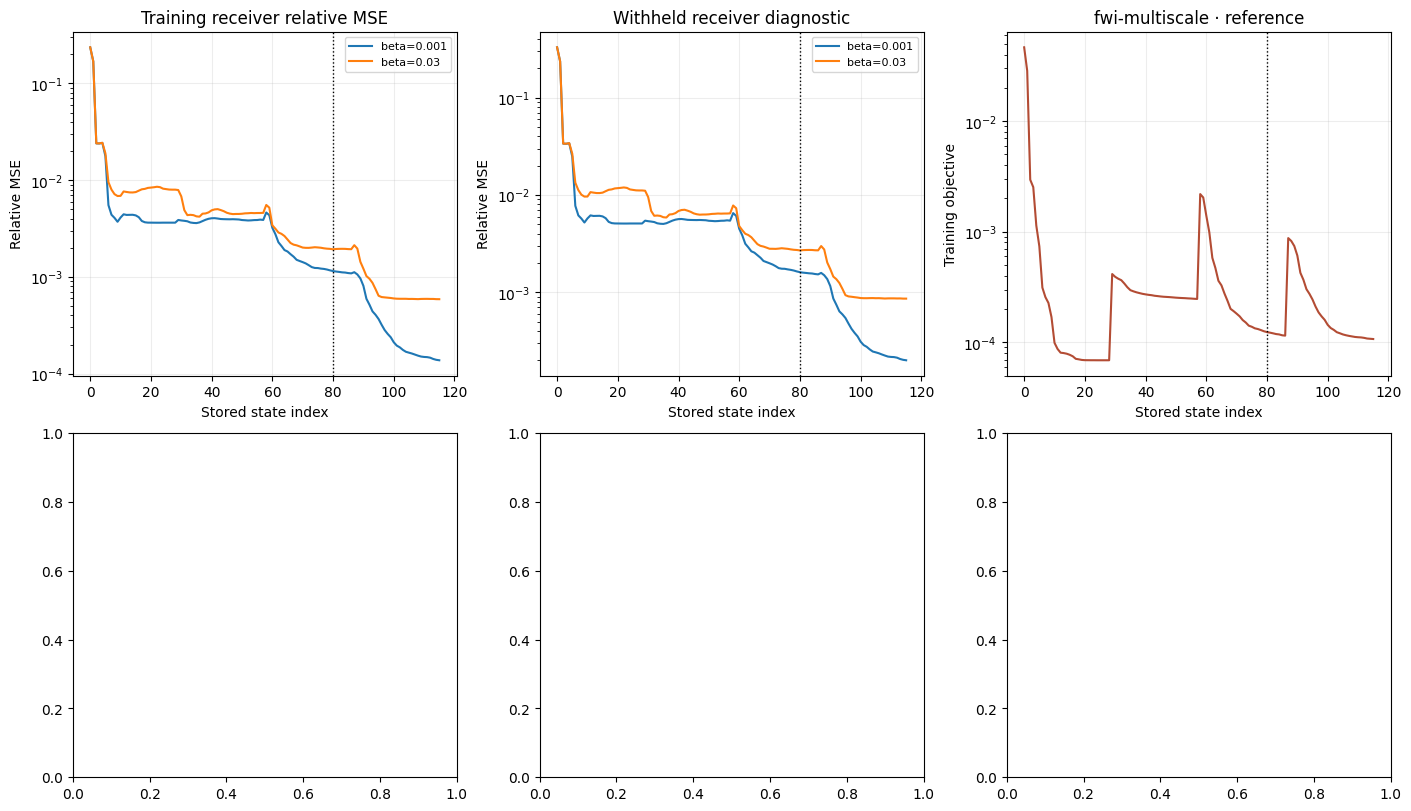

In [4]:
# Plot the recorded evolution of objective, model, residual, and step diagnostics.
fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
for label, rows in trajectories.items():
    x = np.arange(len(rows))
    axes[0, 0].plot(x, [r["active_relative_mse"] for r in rows], label=label)
    axes[0, 1].plot(x, [r["withheld_relative_mse"] for r in rows], label=label)
for ax, title in zip(axes[0, :2], ["Training receiver relative MSE", "Withheld receiver diagnostic"]):
    ax.axvline(STATE_INDEX, color="black", ls=":", lw=1)
    ax.set(xlabel="Stored state index", ylabel="Relative MSE", title=title)
    ax.set_yscale("log")
    ax.grid(alpha=0.22)
    ax.legend(fontsize=8)
axes[0, 2].plot(np.arange(len(records)), [r["objective"] for r in records], color="#b34c34")
axes[0, 2].axvline(STATE_INDEX, color="black", ls=":", lw=1)
axes[0, 2].set(xlabel="Stored state index", ylabel="Training objective", title=f"{METHOD} · {BETA_CASE}")
axes[0, 2].set_yscale("log")
axes[0, 2].grid(alpha=0.22)


### The three panels show stored velocity models for the reference penalty, stronger penalty, and cycle-skip control. Shared distance/depth axes and velocity units make geometry comparable, but color and smoothness do not establish data fit. Read each image beside its objective and withheld error; the salt challenge is intentionally retained as a negative control.

Los tres paneles muestran modelos de velocidad guardados para la penalización de referencia, una mayor y el control con salto de ciclo. Los ejes comunes de distancia y profundidad permiten comparar geometría, pero color y suavidad no prueban ajuste a datos. Lea cada imagen junto con objetivo y error retenido; el caso de sal se conserva como control negativo.

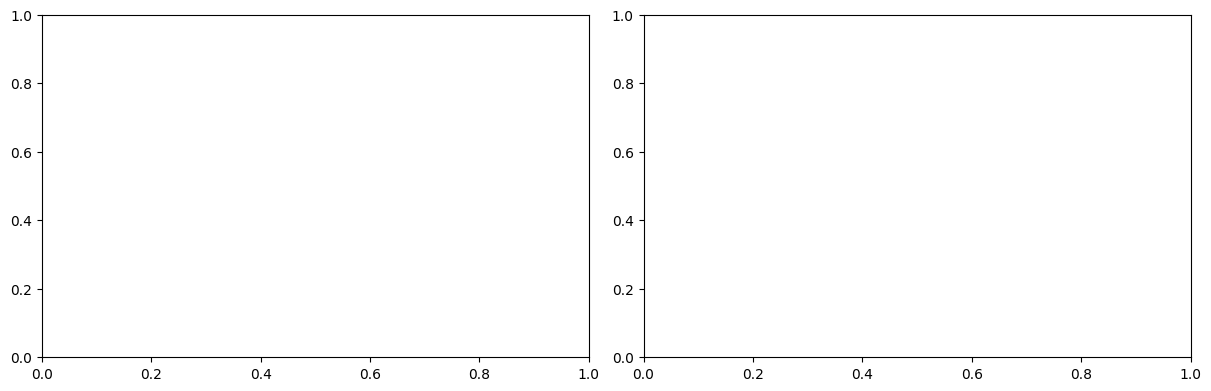

In [5]:
for ax, case, title in [
    (axes[1, 0], layered, "Layered · reference beta"),
    (axes[1, 1], strong, "Layered · stronger beta"),
    (axes[1, 2], challenge, "Salt cycle-skip negative control"),
]:
    model = np.asarray(case["methods"][METHOD]["model"])
    im = ax.imshow(
        model,
        origin="upper",
        aspect="auto",
        extent=[0, model.shape[1] * case["grid"]["spacing"][1], model.shape[0] * case["grid"]["spacing"][0], 0],
        cmap="viridis",
    )
    ax.set(title=title, xlabel="Distance (m)", ylabel="Depth (m)")
    fig.colorbar(im, ax=ax, label="Velocity (m/s)")
plt.show()
# Receiver 12 is withheld because 12 mod 5 equals 2.
shot, receiver = 0, 12
assert receiver % 5 == 2
time_s = np.arange(len(layered["observed"][shot][receiver])) * layered["dt"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)


### Receiver 12 is selected by the recorded modulo-five withholding rule. Comparing its observed and predicted waveform exposes phase and timing mismatch that a scalar objective can hide; the filled residual is diagnostic, not an independent validation set. Because these are saved synthetic gathers, the plot cannot establish field FWI performance or current solver reproducibility.

El receptor 12 se selecciona mediante la regla registrada de retención módulo cinco. Comparar su forma de onda observada y predicha revela desajustes de fase y tiempo que un objetivo escalar puede ocultar; el residuo sombreado es diagnóstico y no una validación independiente. Los gathers son sintéticos guardados y no demuestran desempeño FWI de campo ni reproducibilidad actual del solver.

In [6]:
# Compare one layered recovery with the separately defined cycle-skip challenge.
for a, case, title in [(ax[0], layered, "Layered recovery"), (ax[1], challenge, "Cycle-skip challenge")]:
    observed = np.asarray(case["observed"])[shot, receiver]
    predicted = np.asarray(case["methods"][METHOD]["predicted"])[shot, receiver]
    a.plot(time_s, observed, color="#202d34", lw=1, label="synthetic observed")
    a.plot(time_s, predicted, color="#d36c3b", lw=1, label="predicted")
    a.fill_between(time_s, observed - predicted, 0, color="#7189a0", alpha=0.22, label="residual")
    a.set(title=title, xlabel="Time (s)", ylabel="Pressure amplitude")
    a.grid(alpha=0.2)
    a.legend(fontsize=8)
plt.show()
print("Receiver 12 was excluded from fitting; waveform residual is diagnostic only.")
print("Preserved cycle-skip verdict:", challenge["methods"][METHOD]["evaluation"])


Receiver 12 was excluded from fitting; waveform residual is diagnostic only.
Preserved cycle-skip verdict: {'status': 'negative-control', 'reason_codes': ['salt_cycle_skipping_challenge'], 'criterion': 'whole-model and active/withheld waveform improve the independent start; active/withheld WRMS <= 2', 'scope': 'synthetic baseline improvement and declared-noise consistency, not exact geology or field validation', 'optimizer_status': 'finite_budget'}


### Independent start

This cell executes a public pipeline operation on the declared inputs.   


In [7]:
# Execute the named pipeline method on the declared lesson input.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
import torch, seismic

model_shape = np.asarray(layered["methods"][METHOD]["model"]).T.shape
start_model = seismic.independent_start(model_shape)
print("start shape and m/s range", start_model.shape, float(start_model.min()), float(start_model.max()))


start shape and m/s range (128, 96) 1800.0 2845.0


### Low-pass method

This cell executes a public pipeline operation on the declared inputs.   


In [8]:
# Execute the named pipeline method on the declared lesson input.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
obs_tensor = torch.as_tensor(np.asarray(layered["observed"]), dtype=torch.float32)
filtered_tensor = seismic.lowpass(obs_tensor, 5.0, dt=float(layered["dt"]))
print("filtered relative energy", float(filtered_tensor.square().mean() / obs_tensor.square().mean()))


filtered relative energy 0.17749862372875214


### Physical roughness

This cell executes a public pipeline operation on the declared inputs.   


In [9]:
# Execute the named pipeline method on the declared lesson input.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
state_tensor = torch.as_tensor(np.asarray(layered["methods"][METHOD]["model"]), dtype=torch.float32)
roughness_value = seismic.physical_roughness(state_tensor)
print("scaled roughness", float(roughness_value))


scaled roughness 0.09156230837106705


### Recovery rules

This cell executes a public pipeline operation on the declared inputs.   


In [10]:
# Execute the named pipeline method on the declared lesson input.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
verdict = seismic.recovery_evaluation(layered["methods"][METHOD]["metrics"])
print("replayed verdict", verdict["status"], verdict["reason_codes"])


replayed verdict recovered []


### Cycle-skip negative control

This cell executes a public pipeline operation on the declared inputs.   


In [11]:
# Execute the named pipeline method on the declared lesson input.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
challenge_verdict = seismic.recovery_evaluation(challenge["methods"][METHOD]["metrics"], challenge=True)
print("negative control", challenge_verdict["status"], challenge_verdict["reason_codes"])


negative control negative-control ['salt_cycle_skipping_challenge']




## Results

**Answer:** At stored FWI state 80, active and withheld relative MSE are 0.001149 and 0.001612. The salt cycle-skip remains a negative control. These are replayed states; the notebook ran no new inversion.

## Summary

The layered cases preserve their recorded updates and the challenge failure instead of presenting a successful-looking snapshot alone. A fresh solve, independent acquisition validation and the field survey are outside this replay.

## References

- [Deepwave acoustic FWI example](https://www.ausargeo.com/deepwave/example_fwi)
- Solver, objective, state history and evaluation: data-pipeline/seismic.py
- Synthetic artifacts: data/derived/v2/FWI_LAYERED/ and data/derived/v2/FWI_CYCLE_SKIP/

**Answer:** At stored state 80, training and withheld relative MSE are 0.001149 and 0.001612. The salt cycle-skip case remains a negative control. These are replayed solver states; this notebook ran no new inversion.
